In [32]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-07


In [33]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_penrose']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 0.00250s


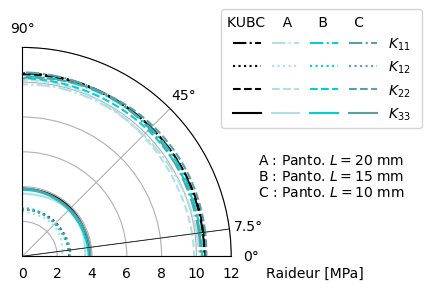

In [82]:


K_0 = np.array(data_bulk['penrose_3'].K_plane_stress_KUBC)


plt.subplots(subplot_kw={'projection': 'polar'},figsize=(5,3))
offset=7.5

K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['k-.', 'k:', 'k--', 'k-']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],label=r'$K_3$')

# * * * * * * * * * *
K_0 = np.array(data_bulk['penrose_1'].K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color='powderblue' ,label=r'$K_3$')
# * * * * * * * * * *
K_0 = np.array(data_bulk['penrose_2'].K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color='darkturquoise' ,label=r'$K_3$')
# * * * * * * * * * *
K_0 = np.array(data_bulk['penrose_3'].K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color='cadetblue' ,label=coeff_name[c_i])

# * * * * * * * *
plt.plot([offset/180*pi]*2,[0,12],'k-',lw=0.5)

ax=plt.gca()
ax.set_thetagrids((0,7.5,45,90,135,180,225,270,315),[f'{i}°' for i in [0,7.5,45,90,135,180,225,270,315]])
ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

# ax.set_rticks([20,40,60,80])
# ax.set_rlabel_position(-22.5)  


l=plt.legend(title=r'KUBC    A      B      C            ',ncol=4,columnspacing=-1.2,
           loc='center left', bbox_to_anchor=(0.92, 0.9))
plt.ylim((0,12))
ax.set_thetamin(0)
ax.set_thetamax(90)

plt.text(-0.04,14, 'Raideur [MPa]', va='top')
plt.text(0.25,14, f'A : Panto. {r"$L=20$"} mm\nB : Panto. {r"$L=15$"} mm\nC : Panto. {r"$L=10$"} mm')


for text in l.get_texts()[:12]:
    text.set_color("white")
plt.tight_layout()
plt.savefig('images/penrose_polar.pdf')

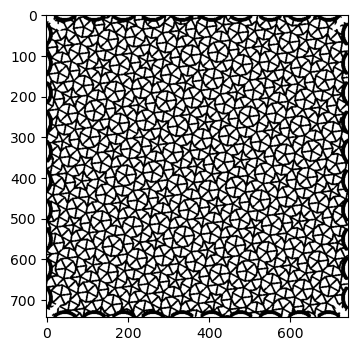

In [36]:
data_bulk['penrose_3'].show_geo()

In [37]:

test.K_panto_dic

[[10.22852266419949, 2.6849762995455597, 0.02756473742510652],
 [2.761082543687664, 10.594499644654901, 0.04370824741878171],
 [0.05181334911231458, 0.042984919082176144, 3.907920303004688]]